In [1]:
#Step 1 — Import the required libraries
# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Warnings and display settings
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", palette="Set2")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
#Step 2 — Load your dataset
file_path = r"D:\College\SY\R\R FA2 data set (2020-25) .csv"

raw_df = pd.read_csv(file_path, low_memory=False)  # what is low_memory??

print("Dataset loaded successfully!")
print("Original shape:", raw_df.shape)  # explain this

display(raw_df.head())

Dataset loaded successfully!
Original shape: (39928, 58)


,Record_ID,City,State,Region,City_Category,Year,Month,Season,Population,Population_Density,Urbanization_Rate,Waste_Type,Daily_Waste_Generation_Tons,Waste_Per_Capita_KG,Collection_Efficiency_Percentage,Waste_Segregation_Rate,Recycling_Rate,Composting_Rate,Landfill_Dependency_Rate,Waste_Processing_Capacity,Treatment_Method,Municipal_Efficiency_Score,Awareness_Campaigns_Count,Smart_Bins_Count,Waste_Collection_Vehicles,Garbage_Collection_Frequency,Worker_Count,Waste_Management_Budget_INR,Cost_Per_Ton_INR,Carbon_Emission_From_Waste,Landfill_Capacity_Tons,Landfill_Remaining_Capacity,Latitude,Longitude,Air_Quality_Index,Rainfall_MM,Tourism_Impact_Score,Industrial_Activity_Level,Population_Growth_Rate,Sustainability_Index,Waste_Management_Performance_Level,Sustainability_Category,Worker_Count.1,Waste_Management_Budget_INR.1,Cost_Per_Ton_INR.1,Carbon_Emission_From_Waste.1,Landfill_Capacity_Tons.1,Landfill_Remaining_Capacity.1,Latitude.1,Longitude.1,Air_Quality_Index.1,Rainfall_MM.1,Tourism_Impact_Score.1,Industrial_Activity_Level.1,Population_Growth_Rate.1,Sustainability_Index.1,Waste_Management_Performance_Level.1,Sustainability_Category.1
0,WM010480,Agartala,Tripura,Northeast,Tier-3,2020.0,1.0,Winter,200826.0,2499.0,29.8,Organic,22.65,0.115,57.7,41.9,19.5,27.4,47.6,21.17,Landfill,2.9,0.0,21.0,6.0,2.0,250.0,1856298.0,368.0,379.26,44747.0,65.7,23.8315,91.2868,123.0,23.4,4.8,1.9,3.76,33.9,Low,Poor,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,WM010481,Agra,Uttar Pradesh,Central,Tier-1,2020.0,1.0,Winter,1799201.0,12956.2,64.7,Plastic,106.50,0.060,69.8,57.4,48.9,0.7,41.8,123.87,Landfill,5.9,2.0,1344.0,97.0,5.0,5546.0,38060452.0,770.0,1640.97,3064301.0,75.4,27.1767,78.0081,234.0,5.8,10.0,9.2,1.61,47.9,High,Good,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,WM010482,Ahmedabad,Gujarat,West,Metro,2020.0,1.0,Winter,8056484.0,30093.7,88.9,Construction,686.00,0.086,73.7,62.9,46.5,1.3,45.9,627.08,Landfill,7.5,7.0,10534.0,529.0,7.0,28206.0,227936341.0,937.0,10992.78,16733692.0,78.6,23.0225,72.5714,176.0,19.1,8.0,4.7,1.76,50.8,High,Excellent,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,WM010483,Aizawl,Mizoram,Northeast,Tier-3,2020.0,1.0,Winter,55702.0,3683.8,50.9,Organic,6.64,0.117,59.2,55.0,20.1,34.4,44.4,5.92,Landfill,5.3,0.0,5.0,3.0,3.0,95.0,407468.0,323.0,117.39,115388.0,69.4,23.7271,92.7176,121.0,33.4,3.3,1.5,3.89,43.5,Low,Average,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,WM010484,Aizawl,Mizoram,Northeast,Tier-3,2020.0,1.0,Winter,55702.0,3683.8,50.9,Paper,1.19,0.022,46.6,63.3,58.8,3.9,32.8,1.05,Recycling,5.3,0.0,5.0,3.0,3.0,95.0,407468.0,535.0,4.08,115388.0,69.4,23.7271,92.7176,121.0,33.4,3.3,1.5,3.89,52.9,Medium,Excellent,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
#Step 3 — Understand the original dataset
print("Number of rows and columns:", raw_df.shape)

print("\nData types:")
raw_df.info()

print("\nFirst 5 records:")
display(raw_df.head())

print("\nLast 5 records:")
display(raw_df.tail())

print("\nSummary statistics:")
display(raw_df.describe(include="all").T)

Number of rows and columns: (39928, 58)

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39928 entries, 0 to 39927
Data columns (total 58 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Record_ID                             38928 non-null  object 
 1   City                                  38928 non-null  object 
 2   State                                 38928 non-null  object 
 3   Region                                38928 non-null  object 
 4   City_Category                         38928 non-null  object 
 5   Year                                  38928 non-null  float64
 6   Month                                 38928 non-null  float64
 7   Season                                38928 non-null  object 
 8   Population                            38928 non-null  float64
 9   Population_Density                    38928 non-null  float64
 10  Urbanization_Rate            

,Record_ID,City,State,Region,City_Category,Year,Month,Season,Population,Population_Density,Urbanization_Rate,Waste_Type,Daily_Waste_Generation_Tons,Waste_Per_Capita_KG,Collection_Efficiency_Percentage,Waste_Segregation_Rate,Recycling_Rate,Composting_Rate,Landfill_Dependency_Rate,Waste_Processing_Capacity,Treatment_Method,Municipal_Efficiency_Score,Awareness_Campaigns_Count,Smart_Bins_Count,Waste_Collection_Vehicles,Garbage_Collection_Frequency,Worker_Count,Waste_Management_Budget_INR,Cost_Per_Ton_INR,Carbon_Emission_From_Waste,Landfill_Capacity_Tons,Landfill_Remaining_Capacity,Latitude,Longitude,Air_Quality_Index,Rainfall_MM,Tourism_Impact_Score,Industrial_Activity_Level,Population_Growth_Rate,Sustainability_Index,Waste_Management_Performance_Level,Sustainability_Category,Worker_Count.1,Waste_Management_Budget_INR.1,Cost_Per_Ton_INR.1,Carbon_Emission_From_Waste.1,Landfill_Capacity_Tons.1,Landfill_Remaining_Capacity.1,Latitude.1,Longitude.1,Air_Quality_Index.1,Rainfall_MM.1,Tourism_Impact_Score.1,Industrial_Activity_Level.1,Population_Growth_Rate.1,Sustainability_Index.1,Waste_Management_Performance_Level.1,Sustainability_Category.1
0,WM010480,Agartala,Tripura,Northeast,Tier-3,2020.0,1.0,Winter,200826.0,2499.0,29.8,Organic,22.65,0.115,57.7,41.9,19.5,27.4,47.6,21.17,Landfill,2.9,0.0,21.0,6.0,2.0,250.0,1856298.0,368.0,379.26,44747.0,65.7,23.8315,91.2868,123.0,23.4,4.8,1.9,3.76,33.9,Low,Poor,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,WM010481,Agra,Uttar Pradesh,Central,Tier-1,2020.0,1.0,Winter,1799201.0,12956.2,64.7,Plastic,106.50,0.060,69.8,57.4,48.9,0.7,41.8,123.87,Landfill,5.9,2.0,1344.0,97.0,5.0,5546.0,38060452.0,770.0,1640.97,3064301.0,75.4,27.1767,78.0081,234.0,5.8,10.0,9.2,1.61,47.9,High,Good,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,WM010482,Ahmedabad,Gujarat,West,Metro,2020.0,1.0,Winter,8056484.0,30093.7,88.9,Construction,686.00,0.086,73.7,62.9,46.5,1.3,45.9,627.08,Landfill,7.5,7.0,10534.0,529.0,7.0,28206.0,227936341.0,937.0,10992.78,16733692.0,78.6,23.0225,72.5714,176.0,19.1,8.0,4.7,1.76,50.8,High,Excellent,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,WM010483,Aizawl,Mizoram,Northeast,Tier-3,2020.0,1.0,Winter,55702.0,3683.8,50.9,Organic,6.64,0.117,59.2,55.0,20.1,34.4,44.4,5.92,Landfill,5.3,0.0,5.0,3.0,3.0,95.0,407468.0,323.0,117.39,115388.0,69.4,23.7271,92.7176,121.0,33.4,3.3,1.5,3.89,43.5,Low,Average,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,WM010484,Aizawl,Mizoram,Northeast,Tier-3,2020.0,1.0,Winter,55702.0,3683.8,50.9,Paper,1.19,0.022,46.6,63.3,58.8,3.9,32.8,1.05,Recycling,5.3,0.0,5.0,3.0,3.0,95.0,407468.0,535.0,4.08,115388.0,69.4,23.7271,92.7176,121.0,33.4,3.3,1.5,3.89,52.9,Medium,Excellent,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Last 5 records:


,Record_ID,City,State,Region,City_Category,Year,Month,Season,Population,Population_Density,Urbanization_Rate,Waste_Type,Daily_Waste_Generation_Tons,Waste_Per_Capita_KG,Collection_Efficiency_Percentage,Waste_Segregation_Rate,Recycling_Rate,Composting_Rate,Landfill_Dependency_Rate,Waste_Processing_Capacity,Treatment_Method,Municipal_Efficiency_Score,Awareness_Campaigns_Count,Smart_Bins_Count,Waste_Collection_Vehicles,Garbage_Collection_Frequency,Worker_Count,Waste_Management_Budget_INR,Cost_Per_Ton_INR,Carbon_Emission_From_Waste,Landfill_Capacity_Tons,Landfill_Remaining_Capacity,Latitude,Longitude,Air_Quality_Index,Rainfall_MM,Tourism_Impact_Score,Industrial_Activity_Level,Population_Growth_Rate,Sustainability_Index,Waste_Management_Performance_Level,Sustainability_Category,Worker_Count.1,Waste_Management_Budget_INR.1,Cost_Per_Ton_INR.1,Carbon_Emission_From_Waste.1,Landfill_Capacity_Tons.1,Landfill_Remaining_Capacity.1,Latitude.1,Longitude.1,Air_Quality_Index.1,Rainfall_MM.1,Tourism_Impact_Score.1,Industrial_Activity_Level.1,Population_Growth_Rate.1,Sustainability_Index.1,Waste_Management_Performance_Level.1,Sustainability_Category.1
39923,WM025199,Vellore,Tamil Nadu,South,Tier-2,2026.0,12.0,Winter,1034017.0,6645.3,60.7,Organic,168.71,0.157,66.8,68.0,24.5,37.6,37.5,149.29,Landfill,6.1,2.0,593.0,38.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2181.0,17944612.0,547.0,2944.26,1786455.0,46.3,12.9165,79.1325,148.0,28.8,3.5,5.7,1.90,48.6,Medium,Good
39924,WM025200,Vijayawada,Andhra Pradesh,South,Tier-1,2026.0,12.0,Winter,3562918.0,6654.0,68.3,Paper,149.86,0.044,80.8,76.5,69.0,5.0,20.4,135.93,Recycling,8.2,5.0,4086.0,201.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11404.0,106000000.0,1385.0,502.45,2925202.0,58.6,16.5062,80.6480,159.0,63.9,4.8,8.7,1.03,70.5,High,Excellent
39925,WM025201,Visakhapatnam,Andhra Pradesh,South,Tier-1,2026.0,12.0,Winter,1623943.0,10731.6,88.1,Paper,68.63,0.041,73.3,63.5,56.8,4.3,37.0,61.37,Landfill,5.7,2.0,2479.0,86.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3896.0,51442109.0,703.0,1189.98,1802175.0,42.5,17.6868,83.2185,208.0,28.3,2.9,8.7,1.05,51.8,High,Excellent
39926,WM025202,Warangal,Telangana,South,Tier-2,2026.0,12.0,Winter,1375417.0,3300.9,56.2,Organic,222.22,0.157,74.2,50.8,28.2,30.3,41.7,236.85,Composting,4.8,1.0,924.0,47.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2864.0,21623684.0,634.0,563.43,741506.0,38.1,17.9689,79.5941,145.0,43.4,5.7,2.9,2.98,44.9,Medium,Good
39927,WM025203,Warangal,Telangana,South,Tier-2,2026.0,12.0,Winter,1375417.0,3300.9,56.2,Plastic,67.94,0.048,60.4,61.0,42.0,1.1,56.3,59.53,Recycling,4.8,1.0,924.0,47.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2864.0,21623684.0,957.0,245.23,741506.0,38.1,17.9689,79.5941,145.0,43.4,5.7,2.9,2.98,40.4,Medium,Average



Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Record_ID,38928,24204,WM010480,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,38928,130,Puri,324,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,38928,36,Uttar Pradesh,4201,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,38928,6,Central,8428,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City_Category,38928,4,Tier-2,13471,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,38928.0,NaN,NaN,NaN,2021.587469,3.108167,2015.0,2020.0,2022.0,2024.0,2026.0
Month,38928.0,NaN,NaN,NaN,6.573854,3.447099,1.0,4.0,7.0,10.0,12.0
Season,38928,3,Winter,16230,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Population,38928.0,NaN,NaN,NaN,1879301.378262,3159966.197829,41365.0,349585.25,950238.5,2001673.0,20838486.0
Population_Density,38928.0,NaN,NaN,NaN,7550.187138,6217.963841,628.2,3259.6,5883.2,10424.2,35197.1


In [6]:
#Step 4 — Correct the dataset structure
df = raw_df.copy()

# Combine columns with duplicated names ending in ".1"
duplicate_suffix_columns = [
    col for col in df.columns if col.endswith(".1")
]

for col in duplicate_suffix_columns:
    original_col = col[:-2]

    if original_col in df.columns:
        df[original_col] = df[original_col].combine_first(df[col])

# Remove the extra duplicate-suffix columns
df = df.drop(columns=duplicate_suffix_columns)

# Remove rows without a Record_ID
df = df.dropna(subset=["Record_ID"])

# Report repeated IDs before removing duplicates
print("Repeated Record_ID rows before cleaning:",
      df["Record_ID"].duplicated().sum())

# Keep the most complete record for each ID
df["_non_missing_count"] = df.notna().sum(axis=1)
df = df.sort_values("_non_missing_count", ascending=False)
df = df.drop_duplicates(subset="Record_ID", keep="first")
df = df.drop(columns="_non_missing_count")

# Reset row numbering
df = df.reset_index(drop=True)

print("\nShape after structural cleaning:", df.shape)
print("Unique Record_ID values:", df["Record_ID"].nunique())

display(df.head())

Repeated Record_ID rows before cleaning: 14724

Shape after structural cleaning: (24204, 42)
Unique Record_ID values: 24204


,Record_ID,City,State,Region,City_Category,Year,Month,Season,Population,Population_Density,Urbanization_Rate,Waste_Type,Daily_Waste_Generation_Tons,Waste_Per_Capita_KG,Collection_Efficiency_Percentage,Waste_Segregation_Rate,Recycling_Rate,Composting_Rate,Landfill_Dependency_Rate,Waste_Processing_Capacity,Treatment_Method,Municipal_Efficiency_Score,Awareness_Campaigns_Count,Smart_Bins_Count,Waste_Collection_Vehicles,Garbage_Collection_Frequency,Worker_Count,Waste_Management_Budget_INR,Cost_Per_Ton_INR,Carbon_Emission_From_Waste,Landfill_Capacity_Tons,Landfill_Remaining_Capacity,Latitude,Longitude,Air_Quality_Index,Rainfall_MM,Tourism_Impact_Score,Industrial_Activity_Level,Population_Growth_Rate,Sustainability_Index,Waste_Management_Performance_Level,Sustainability_Category
0,WM010480,Agartala,Tripura,Northeast,Tier-3,2020.0,1.0,Winter,200826.0,2499.0,29.8,Organic,22.65,0.115,57.7,41.9,19.5,27.4,47.6,21.17,Landfill,2.9,0.0,21.0,6.0,2.0,250.0,1856298.0,368.0,379.26,44747.0,65.7,23.8315,91.2868,123.0,23.4,4.8,1.9,3.76,33.9,Low,Poor
1,WM012231,Warangal,Telangana,South,Tier-2,2020.0,10.0,Winter,1100993.0,2990.4,53.6,Paper,38.48,0.035,54.4,64.9,50.7,3.9,43.5,35.14,Landfill,4.2,0.0,436.0,47.0,4.0,2155.0,20383974.0,427.0,610.48,701425.0,69.4,17.9689,79.5941,156.0,55.0,3.9,3.2,3.18,47.0,Medium,Good
2,WM012224,Vadodara,Gujarat,West,Tier-1,2020.0,10.0,Winter,2377365.0,11537.5,62.4,Paper,84.43,0.037,73.6,68.3,61.3,4.1,32.5,96.80,Recycling,5.6,1.0,1560.0,105.0,5.0,6010.0,67191165.0,1273.0,289.34,4702938.0,75.4,22.3072,73.1812,158.0,3.8,4.6,6.8,1.82,51.8,High,Excellent
3,WM012225,Varanasi,Uttar Pradesh,Central,Tier-1,2020.0,10.0,Winter,2286316.0,10776.4,78.7,Paper,101.91,0.045,65.7,55.8,49.7,5.0,43.9,103.10,Recycling,6.2,3.0,1520.0,118.0,6.0,6685.0,78340358.0,1319.0,357.12,2566448.0,73.6,25.3176,82.9739,194.0,3.5,9.1,5.9,3.12,45.5,High,Good
4,WM012226,Vellore,Tamil Nadu,South,Tier-2,2020.0,10.0,Winter,925400.0,6145.2,57.0,Construction,51.76,0.056,63.3,54.1,39.7,1.1,54.3,55.60,Recycling,5.7,4.0,324.0,34.0,3.0,1810.0,10745968.0,724.0,171.77,1689890.0,71.7,12.9165,79.1325,165.0,28.9,3.4,5.9,2.24,39.8,Medium,Average


In [7]:
#Step 5 — Check missing values and duplicates
print("Total missing values:", df.isnull().sum().sum())

print("\nMissing values by column:")
missing_values = df.isnull().sum()
display(missing_values[missing_values > 0].sort_values(ascending=False))

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nDuplicate Record_ID values:",
      df["Record_ID"].duplicated().sum())

Total missing values: 0

Missing values by column:


Series([], dtype: int64)


Exact duplicate rows: 0

Duplicate Record_ID values: 0


In [8]:
#You can visualize missing values with a heatmap if any remain:
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]

if len(missing_counts) > 0:
    missing_counts.sort_values().plot(
        kind="barh",
        figsize=(9, 5),
        color="#D946A6"
    )
    plt.title("Missing Values by Column", fontsize=15)
    plt.xlabel("Number of Missing Values")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values remain in the cleaned dataset.")

No missing values remain in the cleaned dataset.


In [10]:
#Step 6 — Check the classification target
target = "Waste_Management_Performance_Level"

print("Target missing values:", df[target].isnull().sum())

print("\nTarget class counts:")
display(df[target].value_counts(dropna=False))

print("\nTarget class percentages:")
display(
    (df[target].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)
#If any target labels are missing, remove those rows from the classification dataset rather than inventing labels.
df = df.dropna(subset=[target]).copy()

print("Rows available for classification:", len(df))

Target missing values: 0

Target class counts:


Waste_Management_Performance_Level
High      8186
Medium    8070
Low       7948
Name: count, dtype: int64


Target class percentages:


Waste_Management_Performance_Level
High      33.82
Medium    33.34
Low       32.84
Name: proportion, dtype: float64

Rows available for classification: 24204


In [11]:
#Step 7 — Numerical descriptive statistics
important_columns = [
    "Daily_Waste_Generation_Tons",
    "Collection_Efficiency_Percentage",
    "Waste_Segregation_Rate",
    "Recycling_Rate",
    "Landfill_Dependency_Rate",
    "Municipal_Efficiency_Score"
]

available_columns = [
    col for col in important_columns if col in df.columns
]

display(df[available_columns].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Daily_Waste_Generation_Tons,24204.0,224.63,564.15,0.09,14.32,54.82,176.54,6487.16
Collection_Efficiency_Percentage,24204.0,62.14,11.47,22.80,54.00,62.10,70.30,99.00
Waste_Segregation_Rate,24204.0,56.25,9.96,15.60,49.50,56.20,63.10,94.10
Recycling_Rate,24204.0,36.80,14.22,5.20,25.70,34.60,45.30,87.50
Landfill_Dependency_Rate,24204.0,45.34,14.66,3.00,34.70,45.50,56.40,90.30
Municipal_Efficiency_Score,24204.0,5.39,1.47,1.70,4.40,5.40,6.30,9.40


Z-score Outlier Analysis
----------------------------------------
Daily_Waste_Generation_Tons: 582 potential outliers
Recycling_Rate: 63 potential outliers
Landfill_Dependency_Rate: 2 potential outliers
Waste_Management_Budget_INR: 730 potential outliers
Carbon_Emission_From_Waste: 327 potential outliers


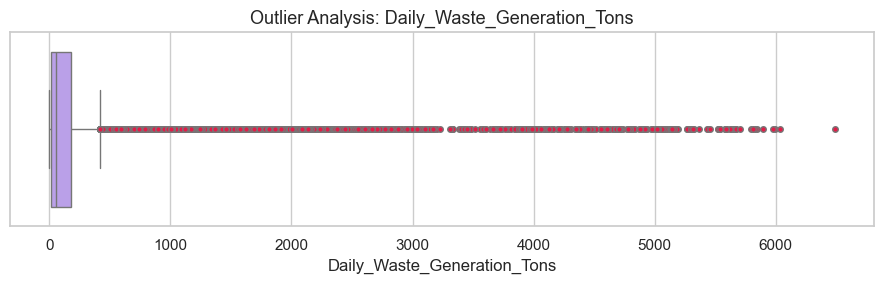

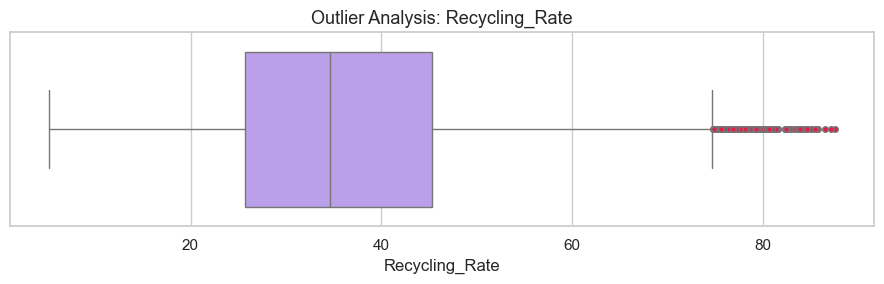

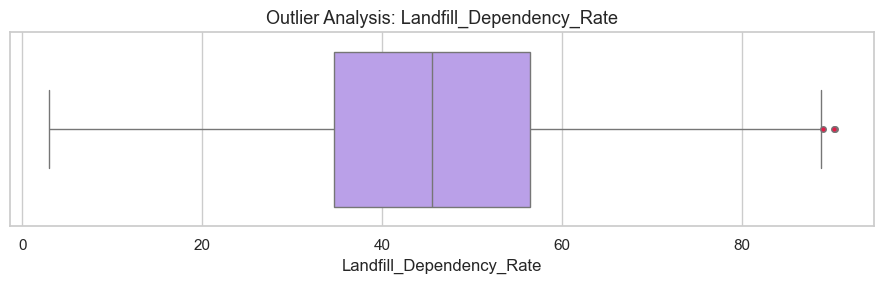

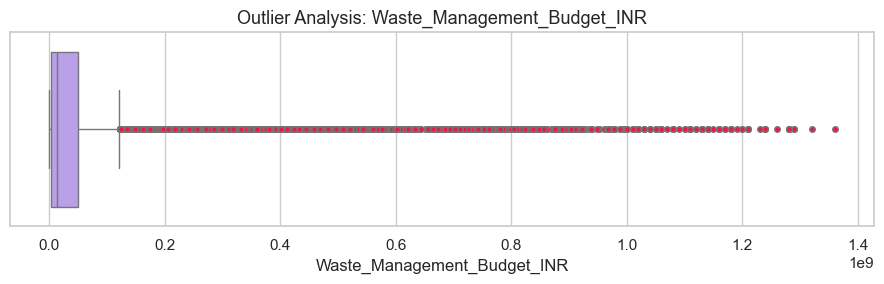

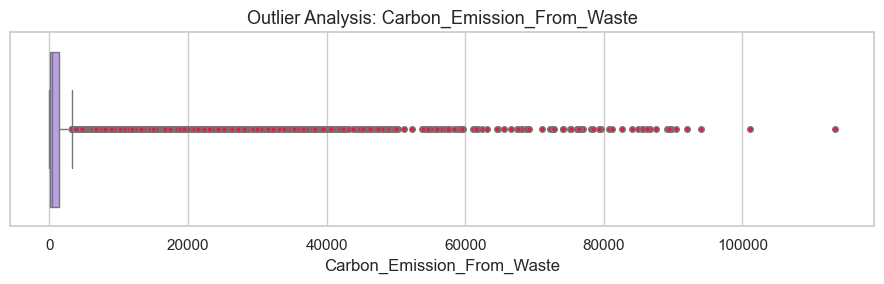

In [12]:
#Step 8 — Z-score outlier analysis
from scipy.stats import zscore

outlier_columns = [
    "Daily_Waste_Generation_Tons",
    "Recycling_Rate",
    "Landfill_Dependency_Rate",
    "Waste_Management_Budget_INR",
    "Carbon_Emission_From_Waste"
]

outlier_columns = [
    col for col in outlier_columns
    if col in df.columns
]

print("Z-score Outlier Analysis")
print("-" * 40)

for col in outlier_columns:
    values = df[col].dropna()

    if len(values) > 1 and values.std() != 0:
        z_scores = zscore(values)
        outlier_count = (np.abs(z_scores) > 3).sum()

        print(f"{col}: {outlier_count} potential outliers")
#Visualize potential outliers using box plots:
for col in outlier_columns:
    plt.figure(figsize=(9, 3))

    sns.boxplot(
        x=df[col],
        color="#B794F4",
        flierprops={
            "marker": "o",
            "markerfacecolor": "#E11D48",
            "markersize": 4
        }
    )

    plt.title(f"Outlier Analysis: {col}", fontsize=13)
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

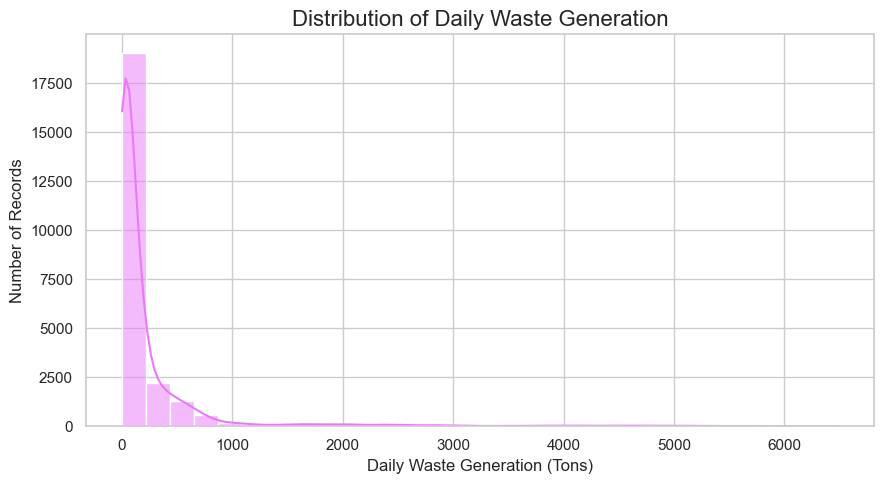

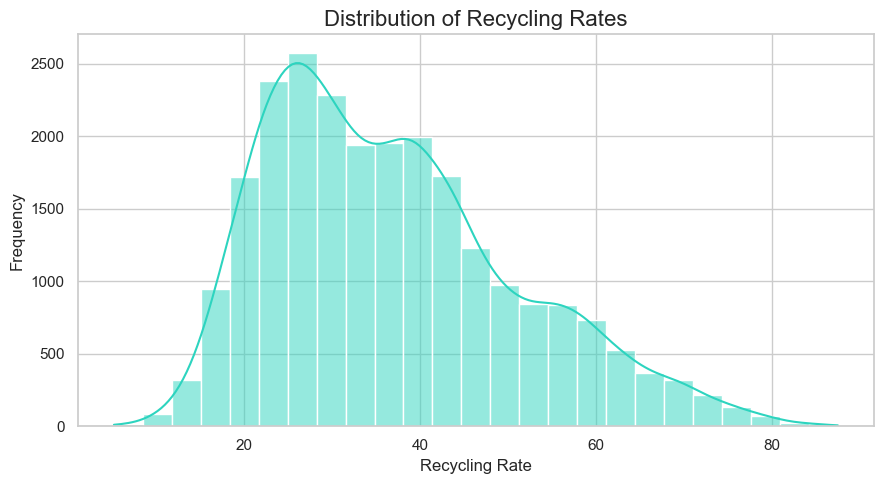

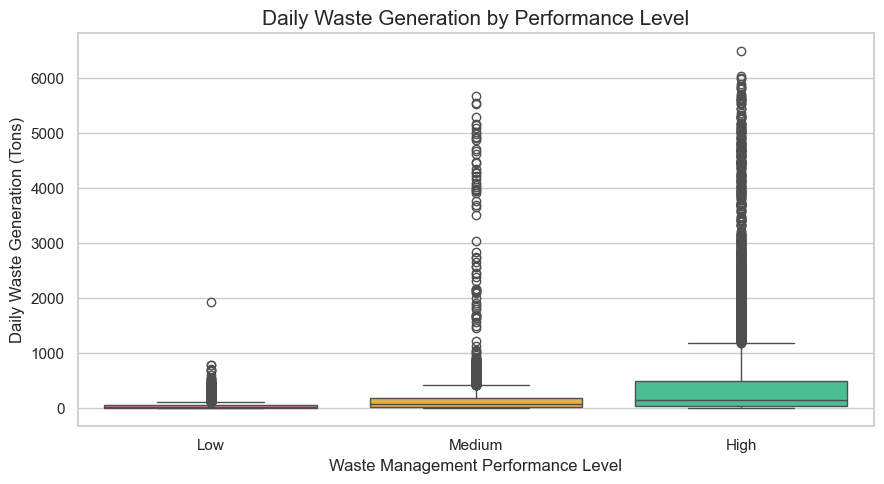

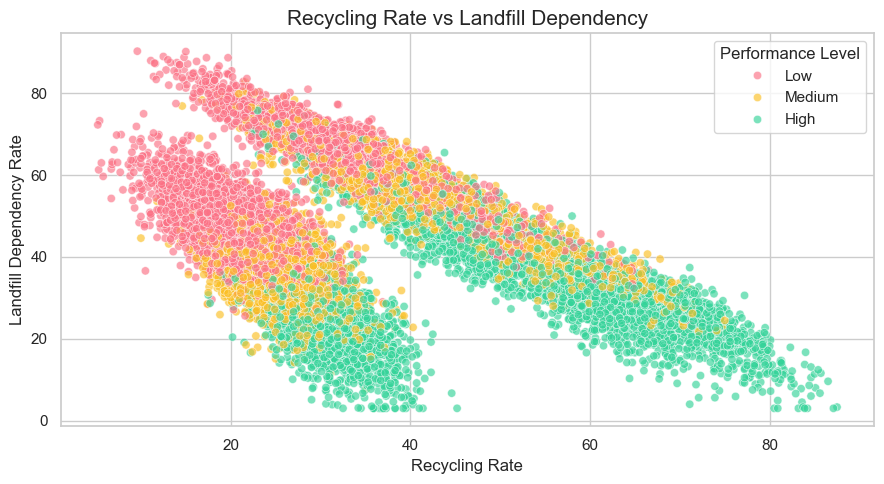

In [14]:
#Step 9 — Create attractive numerical EDA graphs
#Graph 1: Distribution of daily waste generation
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Daily_Waste_Generation_Tons",
    bins=30,
    kde=True,
    color="#E879F9"
)

plt.title("Distribution of Daily Waste Generation", fontsize=16)
plt.xlabel("Daily Waste Generation (Tons)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()
#Graph 2: Distribution of recycling rates
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Recycling_Rate",
    bins=25,
    kde=True,
    color="#2DD4BF"
)

plt.title("Distribution of Recycling Rates", fontsize=16)
plt.xlabel("Recycling Rate")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()
#Graph 3: Waste generation by performance level
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Waste_Management_Performance_Level",
    y="Daily_Waste_Generation_Tons",
    order=["Low", "Medium", "High"],
    hue="Waste_Management_Performance_Level",
    palette=["#FB7185", "#FBBF24", "#34D399"],
    legend=False
)

plt.title("Daily Waste Generation by Performance Level", fontsize=15)
plt.xlabel("Waste Management Performance Level")
plt.ylabel("Daily Waste Generation (Tons)")
plt.tight_layout()
plt.show()
#Graph 4: Relationship between recycling and landfill dependency
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Recycling_Rate",
    y="Landfill_Dependency_Rate",
    hue="Waste_Management_Performance_Level",
    hue_order=["Low", "Medium", "High"],
    palette=["#FB7185", "#FBBF24", "#34D399"],
    alpha=0.65
)

plt.title("Recycling Rate vs Landfill Dependency", fontsize=15)
plt.xlabel("Recycling Rate")
plt.ylabel("Landfill Dependency Rate")
plt.legend(title="Performance Level")
plt.tight_layout()
plt.show()

In [15]:
#Step 10 — Prepare the features for classification
target = "Waste_Management_Performance_Level"

# Columns that must not be used as input features
excluded_columns = [
    "Record_ID",
    "City",
    "Sustainability_Index",
    "Sustainability_Category",
    "Waste_Management_Performance_Level"
]

# Choose useful categorical features
categorical_features = [
    "State",
    "Region",
    "City_Category",
    "Season",
    "Waste_Type",
    "Treatment_Method"
]

categorical_features = [
    col for col in categorical_features
    if col in df.columns and col not in excluded_columns
]

# Choose numerical features
numeric_features = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in excluded_columns
]

# Final list of input features
feature_columns = numeric_features + categorical_features

X = df[feature_columns].copy()
y = df[target].copy()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))
print("Total input features:", len(feature_columns))

print("\nFeatures selected:")
print(feature_columns)

print("\nTarget classes:")
print(y.value_counts())

Number of numerical features: 31
Number of categorical features: 6
Total input features: 37

Features selected:
['Year', 'Month', 'Population', 'Population_Density', 'Urbanization_Rate', 'Daily_Waste_Generation_Tons', 'Waste_Per_Capita_KG', 'Collection_Efficiency_Percentage', 'Waste_Segregation_Rate', 'Recycling_Rate', 'Composting_Rate', 'Landfill_Dependency_Rate', 'Waste_Processing_Capacity', 'Municipal_Efficiency_Score', 'Awareness_Campaigns_Count', 'Smart_Bins_Count', 'Waste_Collection_Vehicles', 'Garbage_Collection_Frequency', 'Worker_Count', 'Waste_Management_Budget_INR', 'Cost_Per_Ton_INR', 'Carbon_Emission_From_Waste', 'Landfill_Capacity_Tons', 'Landfill_Remaining_Capacity', 'Latitude', 'Longitude', 'Air_Quality_Index', 'Rainfall_MM', 'Tourism_Impact_Score', 'Industrial_Activity_Level', 'Population_Growth_Rate', 'State', 'Region', 'City_Category', 'Season', 'Waste_Type', 'Treatment_Method']

Target classes:
Waste_Management_Performance_Level
High      8186
Medium    8070
Low    

In [16]:
#Step 11 — Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training records: 19363
Testing records: 4841

Training class distribution:
Waste_Management_Performance_Level
High      0.338
Medium    0.333
Low       0.328
Name: proportion, dtype: float64

Testing class distribution:
Waste_Management_Performance_Level
High      0.338
Medium    0.333
Low       0.328
Name: proportion, dtype: float64


In [17]:
#Step 12 — Preprocess numerical and categorical data
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing to each type of feature
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [18]:
#Step 13 — Build Model 1: Logistic Regression
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Predict unseen test records
logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression model trained successfully!")
#Step 14 — Build Model 2: Decision Tree Classifier
tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=5,
        random_state=42
    ))
])

# Train the model
tree_model.fit(X_train, y_train)

# Predict unseen test records
tree_predictions = tree_model.predict(X_test)

print("Decision Tree model trained successfully!")
#Step 15 — Evaluate both models
def evaluate_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Macro)": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1-Score (Macro)": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

results = pd.DataFrame([
    evaluate_model(
        "Logistic Regression", y_test, logistic_predictions
    ),
    evaluate_model(
        "Decision Tree", y_test, tree_predictions
    )
])

display(results.round(4))

Logistic Regression model trained successfully!
Decision Tree model trained successfully!


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Logistic Regression,0.9924,0.9924,0.9923,0.9924
1,Decision Tree,0.9035,0.9093,0.9036,0.9048


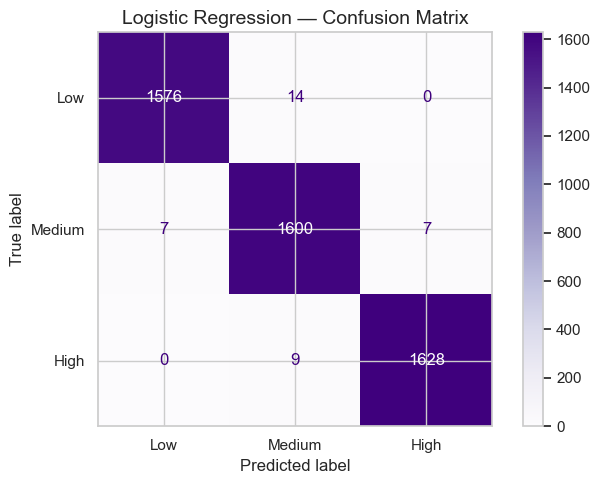

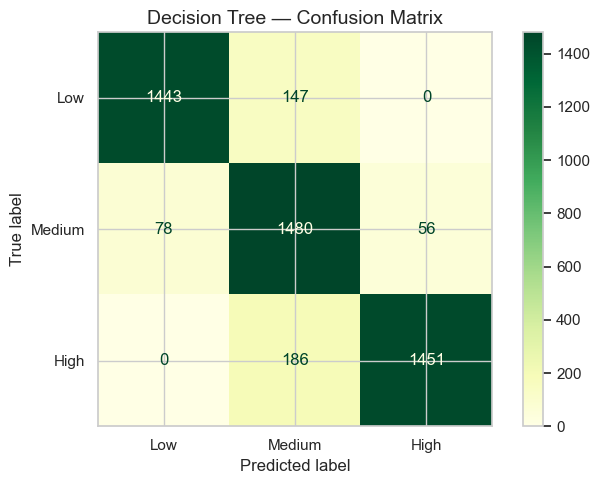

In [19]:
#Step 16 — Create attractive confusion matrices
#Logistic Regression
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    labels=["Low", "Medium", "High"],
    display_labels=["Low", "Medium", "High"],
    cmap="Purples",
    values_format="d",
    ax=ax
)

ax.set_title("Logistic Regression — Confusion Matrix", fontsize=14)
plt.tight_layout()
plt.show()
#Decision Tree
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    tree_predictions,
    labels=["Low", "Medium", "High"],
    display_labels=["Low", "Medium", "High"],
    cmap="YlGn",
    values_format="d",
    ax=ax
)

ax.set_title("Decision Tree — Confusion Matrix", fontsize=14)
plt.tight_layout()
plt.show()

In [20]:
#Step 17 — Generate detailed classification reports
print("=" * 55)
print("LOGISTIC REGRESSION REPORT")
print("=" * 55)

print(classification_report(
    y_test,
    logistic_predictions,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

print("=" * 55)
print("DECISION TREE REPORT")
print("=" * 55)

print(classification_report(
    y_test,
    tree_predictions,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

         Low       1.00      0.99      0.99      1590
      Medium       0.99      0.99      0.99      1614
        High       1.00      0.99      1.00      1637

    accuracy                           0.99      4841
   macro avg       0.99      0.99      0.99      4841
weighted avg       0.99      0.99      0.99      4841

DECISION TREE REPORT
              precision    recall  f1-score   support

         Low       0.95      0.91      0.93      1590
      Medium       0.82      0.92      0.86      1614
        High       0.96      0.89      0.92      1637

    accuracy                           0.90      4841
   macro avg       0.91      0.90      0.90      4841
weighted avg       0.91      0.90      0.90      4841



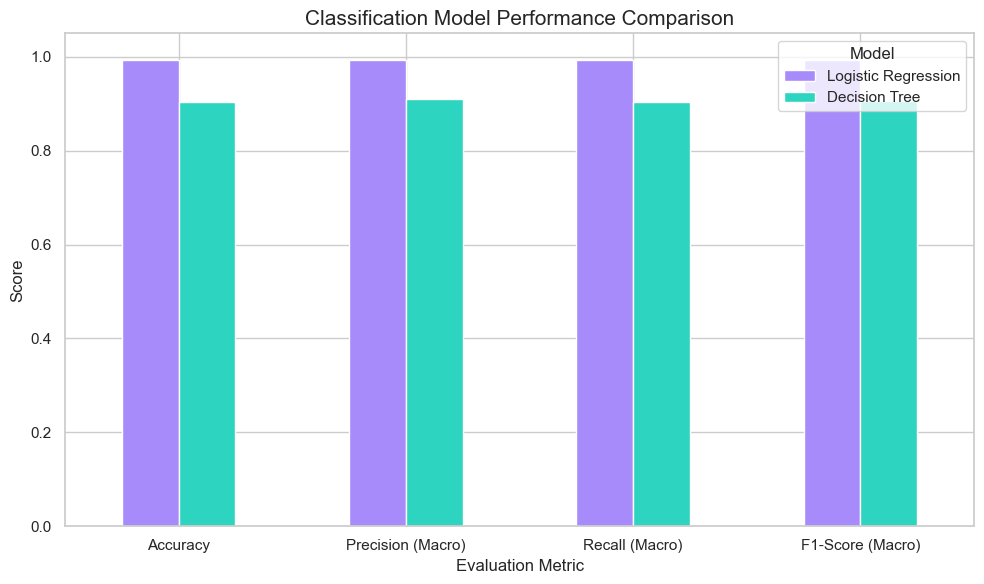

In [21]:
#Step 18 — Compare the models visually
metrics_to_plot = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-Score (Macro)"
]

plot_data = results.set_index("Model")[metrics_to_plot]

ax = plot_data.T.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#A78BFA", "#2DD4BF"],
    edgecolor="white"
)

ax.set_title("Classification Model Performance Comparison", fontsize=15)
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.legend(title="Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [22]:
#Step 19 — Save your results and trained models
import joblib
from pathlib import Path

output_folder = Path("waste_management_outputs")
output_folder.mkdir(exist_ok=True)

# Save cleaned dataset
df.to_csv(
    output_folder / "cleaned_waste_management.csv",
    index=False
)

# Save model comparison
results.to_csv(
    output_folder / "classification_model_comparison.csv",
    index=False
)

# Save trained pipelines, including preprocessing
joblib.dump(
    logistic_model,
    output_folder / "logistic_regression_model.pkl"
)

joblib.dump(
    tree_model,
    output_folder / "decision_tree_model.pkl"
)

# Save the feature list for future use
joblib.dump(
    feature_columns,
    output_folder / "classification_features.pkl"
)

print("Cleaned data, comparison results and models saved successfully!")

Cleaned data, comparison results and models saved successfully!
